In [2]:
!pip install pyspark

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import pandas as pd

caminho = '/content/drive/MyDrive/Projeto_Olist/'

orders = pd.read_csv(caminho + 'olist_orders_dataset.csv')
reviews = pd.read_csv(caminho + 'olist_order_reviews_dataset.csv')
items = pd.read_csv(caminho + 'olist_order_items_dataset.csv')
customers = pd.read_csv(caminho + 'olist_customers_dataset.csv')
sellers = pd.read_csv(caminho + 'olist_sellers_dataset.csv')
products = pd.read_csv(caminho + 'olist_products_dataset.csv')

In [5]:
orders.info()          # tipos de dado e quantidade de nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [6]:
orders.shape           # quantas linhas e colunas

(99441, 8)

In [7]:
orders.isnull().sum()  # quantidade de valores nulos por coluna

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [8]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [9]:
products.isnull().sum()  # quantidade de valores nulos por coluna

,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


In [10]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [11]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [12]:
# Ver quantos pedidos não têm data de entrega (não foram entregues ainda)
orders['order_delivered_customer_date'].isnull().sum()

np.int64(2965)

In [13]:
# Ver os tipos de status de pedido existentes
orders['order_status'].value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [14]:
# Ver distribuição das notas de review
reviews['review_score'].value_counts()

,count
review_score,
5,57328
4,19142
1,11424
3,8179
2,3151


In [15]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [16]:
reviews.isnull().sum()

,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


In [17]:
colunas_de_data = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for coluna in colunas_de_data:
    orders[coluna] = pd.to_datetime(orders[coluna], errors='coerce')

In [18]:
orders[colunas_de_data].dtypes

,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


In [19]:
# Verifica quantos pedidos não têm data de entrega
print(orders['order_delivered_customer_date'].isnull().sum())

# Cria um dataframe só com pedidos efetivamente entregues (pra análise de atraso)
orders_entregues = orders[orders['order_delivered_customer_date'].notnull()].copy()

2965


In [20]:
#substitui por um marcador
reviews['review_comment_message'] = reviews['review_comment_message'].fillna('Sem comentário')
reviews['review_comment_title'] = reviews['review_comment_title'].fillna('Sem título')

In [21]:
reviews['review_score'].isnull().sum()

np.int64(0)

In [22]:
print(orders.duplicated().sum())
print(reviews.duplicated().sum())
print(items.duplicated().sum())

# Se houver duplicatas exatas, remove
orders = orders.drop_duplicates()
reviews = reviews.drop_duplicates()
items = items.drop_duplicates()

0
0
0


In [23]:
orders_entregues.isnull().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,14
order_delivered_carrier_date,1
order_delivered_customer_date,0
order_estimated_delivery_date,0


In [24]:
reviews.isnull().sum()

,0
review_id,0
order_id,0
review_score,0
review_comment_title,0
review_comment_message,0
review_creation_date,0
review_answer_timestamp,0


In [25]:
orders_entregues['atraso_dias'] = (
    orders_entregues['order_delivered_customer_date'] -
    orders_entregues['order_estimated_delivery_date']
).dt.days

In [26]:
orders_entregues['status_entrega'] = orders_entregues['atraso_dias'].apply(
    lambda x: 'Atrasado' if x > 0 else 'No Prazo'
)

In [27]:
orders_entregues.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,atraso_dias,status_entrega
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,-8,No Prazo
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,-6,No Prazo
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,-18,No Prazo
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,-13,No Prazo
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,-10,No Prazo


Como interpretar o resultado:
*   Valor positivo → pedido chegou depois do prazo (atrasado)
*   Valor negativo → pedido chegou antes do prazo
*   Valor zero → chegou exatamente no dia estimado



In [28]:
orders_entregues['atraso_dias'].describe()

,atraso_dias
count,96476.000000
mean,-11.876881
std,10.183854
min,-147.000000
25%,-17.000000
50%,-12.000000
75%,-7.000000
max,188.000000


### Visualizando a Distribuição de Atrasos

Visualizando a distribuição da coluna `atraso_dias` para entender melhor a natureza dos atrasos e a extensão do valor máximo (188 dias) e mínimo (-147 dias)

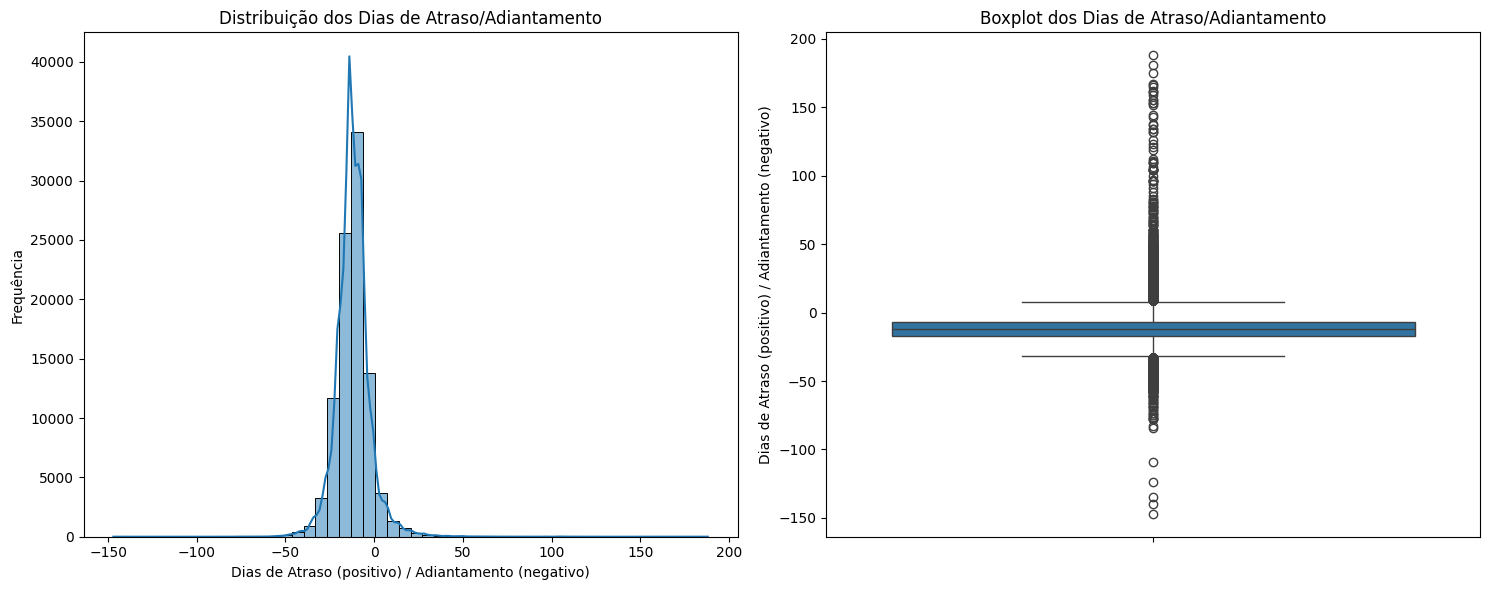

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 6))

# Histograma dos dias de atraso
plt.subplot(1, 2, 1)
sns.histplot(orders_entregues['atraso_dias'], bins=50, kde=True)
plt.title('Distribuição dos Dias de Atraso/Adiantamento')
plt.xlabel('Dias de Atraso (positivo) / Adiantamento (negativo)')
plt.ylabel('Frequência')

# Boxplot dos dias de atraso para identificar outliers
plt.subplot(1, 2, 2)
sns.boxplot(y=orders_entregues['atraso_dias'])
plt.title('Boxplot dos Dias de Atraso/Adiantamento')
plt.ylabel('Dias de Atraso (positivo) / Adiantamento (negativo)')

plt.tight_layout()
plt.show()

In [30]:
orders_entregues.sort_values(by='atraso_dias', ascending=True).head(10)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,atraso_dias,status_entrega
40094,0607f0efea4b566f1eb8f7d3c2397320,a5fbb6579eacbeb02752a143bfe82405,delivered,2018-03-06 09:47:07,2018-03-06 09:55:47,2018-03-07 21:33:39,2018-03-09 23:36:47,2018-08-03,-147,No Prazo
15791,c72727d29cde4cf870d569bf65edabfd,964253ff0e4e08180064764a450e521f,delivered,2017-02-07 18:01:15,2017-02-09 02:50:07,2017-02-10 05:32:55,2017-02-14 14:27:45,2017-07-04,-140,No Prazo
57160,eec7f369423b033e549c02f3c5381205,32cef4bdd6bfa50612d81dc77a93b131,delivered,2018-02-06 20:44:56,2018-02-08 10:10:31,2018-02-15 20:42:12,2018-02-27 16:35:43,2018-07-12,-135,No Prazo
86444,c2bb89b5c1dd978d507284be78a04cb2,6357fffb5704244d552615bbfcea1442,delivered,2017-05-23 22:28:36,2017-05-24 22:35:08,2017-05-29 02:03:28,2017-06-09 13:35:54,2017-10-11,-124,No Prazo
67488,40dc2ba6f322a17626aac6244332828c,6210a37f9d6a265a4f3fbe2c21672a00,delivered,2017-10-05 21:39:05,2017-10-05 21:49:21,2017-10-09 12:13:58,2017-10-13 13:49:07,2018-01-30,-109,No Prazo
79449,1a695d543b7302aa9446c8d5fbd632bf,b882cbae40f34e60a3ec3efefabda4ea,delivered,2017-12-16 10:32:49,2017-12-16 10:55:00,2017-12-19 23:17:45,2017-12-28 22:18:23,2018-03-22,-84,No Prazo
62706,39e0115911bf404857e14baa7f097feb,816642e9995c2461f2172469e78c7370,delivered,2018-01-20 07:48:16,2018-01-20 09:15:46,2018-01-23 18:27:00,2018-02-01 01:52:34,2018-04-25,-83,No Prazo
37491,c5132855100a12d63ed4e8ae05f9594d,6e5b6ba2e8de70d9e920b541a619ba91,delivered,2017-10-13 14:45:03,2017-10-17 04:24:35,2017-10-18 19:37:31,2017-10-25 20:22:10,2018-01-11,-78,No Prazo
95849,559eea5a72341a4c82dbce9884277cb7,5fd5cb96f515996e88d84c61012d97f4,delivered,2017-11-17 10:24:03,2017-11-17 10:51:09,2017-11-20 17:38:35,2017-11-30 16:12:50,2018-02-16,-78,No Prazo
63537,38930f76efb00b138f4d632e4d557341,0f9043c635f86f7eb1e8fc07704df303,delivered,2018-01-28 13:47:42,2018-01-28 14:00:18,2018-02-02 01:42:30,2018-02-08 19:21:39,2018-04-27,-78,No Prazo


In [31]:
orders_entregues['status_entrega'].value_counts(normalize=True) * 100

,proportion
status_entrega,
No Prazo,93.226295
Atrasado,6.773705


In [32]:
# Calcula e exibe a média e a mediana do 'atraso_dias'
mean_atraso = orders_entregues['atraso_dias'].mean()
median_atraso = orders_entregues['atraso_dias'].median()

print(f"Média do atraso_dias: {mean_atraso:.2f} dias")
print(f"Mediana do atraso_dias: {median_atraso:.2f} dias")

Média do atraso_dias: -11.88 dias
Mediana do atraso_dias: -12.00 dias


In [33]:
analise = orders_entregues.merge(
    reviews[['order_id', 'review_score']],
    on='order_id',
    how='inner'
)

In [34]:
analise.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,atraso_dias,status_entrega,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,-8,No Prazo,4
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,-6,No Prazo,4
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,-18,No Prazo,5
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,-13,No Prazo,5
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,-10,No Prazo,5


In [35]:
analise.groupby('status_entrega')['review_score'].mean()

,review_score
status_entrega,
Atrasado,2.271139
No Prazo,4.289842


In [36]:
analise[['atraso_dias', 'review_score']].corr()

,atraso_dias,review_score
atraso_dias,1.000000,-0.266764
review_score,-0.266764,1.000000


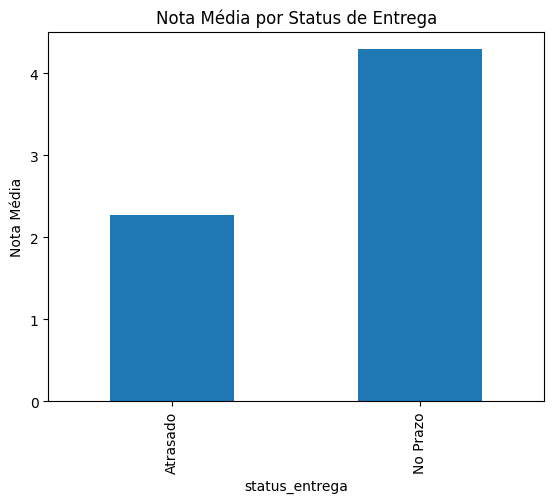

In [37]:
import matplotlib.pyplot as plt

analise.groupby('status_entrega')['review_score'].mean().plot(kind='bar')
plt.title('Nota Média por Status de Entrega')
plt.ylabel('Nota Média')
plt.show()

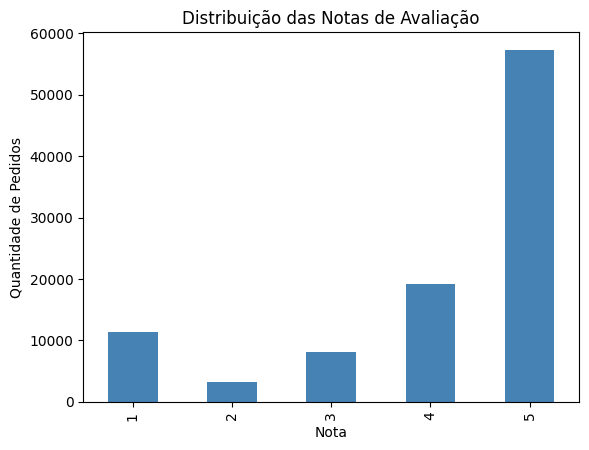

,proportion
review_score,
1,11.513344
2,3.175643
3,8.242965
4,19.291704
5,57.776344


In [38]:
import matplotlib.pyplot as plt

reviews['review_score'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Distribuição das Notas de Avaliação')
plt.xlabel('Nota')
plt.ylabel('Quantidade de Pedidos')
plt.show()

reviews['review_score'].value_counts(normalize=True).sort_index() * 100

In [39]:
# Cria uma coluna de ano-mês a partir da data de compra
analise['ano_mes'] = analise['order_purchase_timestamp'].dt.to_period('M')

tendencia_temporal = analise.groupby('ano_mes').agg(
    pct_atraso=('status_entrega', lambda x: (x == 'Atrasado').mean() * 100),
    nota_media=('review_score', 'mean'),
    total_pedidos=('order_id', 'count')
)

tendencia_temporal

,pct_atraso,nota_media,total_pedidos
ano_mes,,,
2016-09,100.000000,1.000000,1
2016-10,0.743494,3.977695,269
2016-12,0.000000,5.000000,1
2017-01,2.807487,4.205882,748
2017-02,2.543913,4.203513,1651
2017-03,4.445319,4.184500,2542
2017-04,6.445993,4.136324,2296
2017-05,2.786378,4.237546,3553
2017-06,2.928071,4.222470,3142


In [40]:
tendencia_temporal_filtrada = tendencia_temporal[tendencia_temporal['total_pedidos'] >= 100]

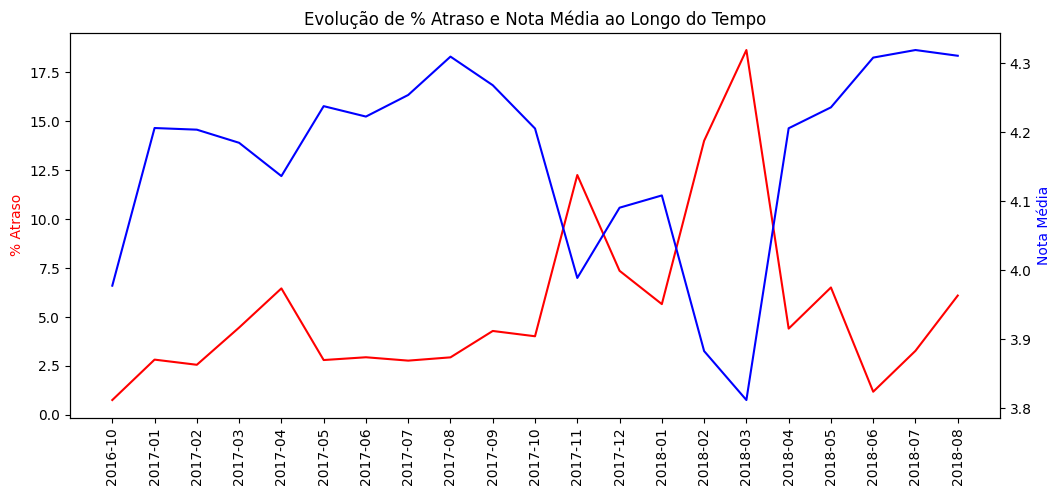

In [41]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(tendencia_temporal_filtrada.index.astype(str), tendencia_temporal_filtrada['pct_atraso'], color='red', label='% Atraso')
ax1.set_ylabel('% Atraso', color='red')
ax1.tick_params(axis='x', rotation=90)

ax2 = ax1.twinx()
ax2.plot(tendencia_temporal_filtrada.index.astype(str), tendencia_temporal_filtrada['nota_media'], color='blue', label='Nota Média')
ax2.set_ylabel('Nota Média', color='blue')

plt.title('Evolução de % Atraso e Nota Média ao Longo do Tempo')
plt.show()

In [42]:
tendencia_temporal_filtrada

,pct_atraso,nota_media,total_pedidos
ano_mes,,,
2016-10,0.743494,3.977695,269
2017-01,2.807487,4.205882,748
2017-02,2.543913,4.203513,1651
2017-03,4.445319,4.184500,2542
2017-04,6.445993,4.136324,2296
2017-05,2.786378,4.237546,3553
2017-06,2.928071,4.222470,3142
2017-07,2.756311,4.253735,3882
2017-08,2.923699,4.309246,4207


In [43]:
# Junta com items pra pegar o product_id de cada pedido
analise_categoria = analise.merge(
    items[['order_id', 'product_id']],
    on='order_id',
    how='inner'
)

# Junta com products pra pegar a categoria
analise_categoria = analise_categoria.merge(
    products[['product_id', 'product_category_name']],
    on='product_id',
    how='inner'
)

# % de atraso por categoria (só categorias com volume mínimo de 100 pedidos, pra evitar ruído)
volume_categoria = analise_categoria['product_category_name'].value_counts()
categorias_relevantes = volume_categoria[volume_categoria >= 100].index

atraso_por_categoria = analise_categoria[
    analise_categoria['product_category_name'].isin(categorias_relevantes)
].groupby('product_category_name').agg(
    pct_atraso=('status_entrega', lambda x: (x == 'Atrasado').mean() * 100),
    nota_media=('review_score', 'mean'),
    total_pedidos=('order_id', 'count')
).sort_values('pct_atraso', ascending=False)

atraso_por_categoria.head(10)

,pct_atraso,nota_media,total_pedidos
product_category_name,,,
audio,11.420613,3.830084,359
fashion_underwear_e_moda_praia,9.523810,4.047619,126
casa_conforto,9.302326,3.851163,430
livros_tecnicos,7.954545,4.393939,264
moveis_escritorio,7.932692,3.517428,1664
eletronicos,7.561785,4.067503,2711
bebes,7.516009,4.079205,2967
construcao_ferramentas_iluminacao,7.508532,4.085324,293
instrumentos_musicais,7.430341,4.222910,646


In [44]:
atraso_por_categoria.tail(10)

,pct_atraso,nota_media,total_pedidos
product_category_name,,,
malas_acessorios,4.100652,4.352283,1073
pcs,4.081633,4.219388,196
alimentos_bebidas,4.059041,4.369004,271
fashion_calcados,3.906250,4.285156,256
market_place,3.630363,4.072607,303
sinalizacao_e_seguranca,3.571429,4.091837,196
telefonia_fixa,3.557312,3.758893,253
climatizacao,3.521127,4.052817,284
agro_industria_e_comercio,3.398058,4.087379,206


In [45]:
analise.to_csv('/content/drive/MyDrive/Projeto_Olist/analise_final.csv', index=False)
atraso_por_categoria.to_csv('/content/drive/MyDrive/Projeto_Olist/atraso_por_categoria.csv', index=True)
tendencia_temporal.to_csv('/content/drive/MyDrive/Projeto_Olist/tendencia_temporal.csv', index=True)

In [46]:
atraso_por_categoria_export = atraso_por_categoria.reset_index()
tendencia_temporal_export = tendencia_temporal.reset_index()

atraso_por_categoria_export.to_csv('/content/drive/MyDrive/Projeto_Olist/atraso_por_categoria.csv', index=False)
tendencia_temporal_export.to_csv('/content/drive/MyDrive/Projeto_Olist/tendencia_temporal.csv', index=False)

In [47]:
analise['ano_mes'] = analise['order_purchase_timestamp'].dt.to_period('M').astype(str)
analise.to_csv('/content/drive/MyDrive/Projeto_Olist/analise_final.csv', index=False)